# Notebook 3: Deep Neural Network and Final Evaluation
## Does a Deep Neural Network Beat Simpler Models at Spotting Diabetes Risk?

**Goal of this notebook:** answer the capstone question directly. We train and tune a deep neural network (DNN), compare it fairly with the three models from Notebook 2 on the same held-out test people, turn the best model into practical screening guidance and explain *which factors drive risk*.

**Contents**
1. Setup and data preparation
2. Neural network design (in plain language)
3. Hyperparameter search for the DNN
4. Learning curves: is the network overfitting?
5. Final comparison of all four models on the test set (with uncertainty)
6. Turning a risk score into a screening policy (choosing a cut-off)
7. What drives risk? (permutation importance + odds ratios)
8. Fairness check: does the model work equally well for different groups?
9. Conclusions, limitations and recommendations

## 1. Setup and Data Preparation

In [1]:
import os, json, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'          # silence TensorFlow start-up messages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             recall_score, precision_score, f1_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)       # reproducible weight initialisation and shuffling
DATA_PATH = '../data/diabetes_012_health_indicators_BRFSS2015.csv'
IMG, RES = '../images/', '../results/'
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


In [2]:
# --- Same cleaning and split as Notebooks 1 and 2 ---
df = pd.read_csv(DATA_PATH)
df['at_risk'] = (df['Diabetes_012'] > 0).astype(int)
df['BMI'] = df['BMI'].clip(upper=60)
df = df.astype(int)

X = df.drop(columns=['Diabetes_012', 'at_risk'])
y = df['at_risk']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

# For the neural network we also carve a 15% VALIDATION slice out of the training set.
# It is used for early stopping and for comparing network designs; the test set stays untouched.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_tr)                # fitted on the training slice ONLY (no leakage)
Xtr_s, Xval_s, Xte_s = scaler.transform(X_tr), scaler.transform(X_val), scaler.transform(X_test)

print(f'Network training: {len(X_tr):,} | validation: {len(X_val):,} | test: {len(X_test):,}')

# Results saved by Notebook 2 (same test rows, same order)
classical = pd.read_csv(RES + 'classical_test_probabilities.csv', index_col=0)
assert (classical.index == X_test.index).all() and (classical['y_true'].values == y_test.values).all()
best_params = json.load(open(RES + 'classical_best_params.json'))
print('Loaded Notebook 2 results:', list(classical.columns[1:]))

Network training: 172,502 | validation: 30,442 | test: 50,736
Loaded Notebook 2 results: ['Logistic Regression', 'Random Forest', 'Gradient Boosting']


## 2. Neural Network Design (in plain language)

A neural network is a stack of layers; each layer mixes the previous layer's numbers into new combinations, so deeper layers can learn *interactions* between questions (e.g., "older **and** high blood pressure **and** difficulty walking"). Our design:

```
21 survey answers (scaled)
   → [Dense layer → Batch normalisation → Dropout]   × 2 or 3 hidden blocks
   → 1 output neuron with a sigmoid  →  a risk score between 0 and 1
```

| Component | Purpose |
|---|---|
| **Dense + ReLU** | The learnable layers that detect combinations of answers |
| **Batch normalization** | Keeps each layer's numbers well-scaled, making training faster and more stable |
| **Dropout** | Randomly switches off a share of neurons during training so the network cannot simply memorize individuals (fights overfitting) |
| **Binary cross-entropy loss + class weights** | The error measure being minimized. Class weights make a missed at-risk person ~5× as costly as a false alarm, matching Notebook 2 |
| **Adam optimizer** | A gradient-descent method that adapts the learning step for each weight |
| **Early stopping** | Training stops once the validation ROC-AUC stops improving for 5 epochs, and the best version is restored |

In [3]:
n_features = Xtr_s.shape[1]
w = len(y_tr) / (2 * np.bincount(y_tr))
class_weight = {0: float(w[0]), 1: float(w[1])}
print('Class weights used in training:', {k: round(v, 2) for k, v in class_weight.items()})

def build_dnn(hidden_units, dropout, learning_rate=1e-3):
    # Build and compile a fully connected network for binary classification
    layers = [tf.keras.layers.Input(shape=(n_features,))]
    for units in hidden_units:
        layers += [tf.keras.layers.Dense(units, activation='relu'),
                   tf.keras.layers.BatchNormalization(),
                   tf.keras.layers.Dropout(dropout)]
    layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                  loss='binary_crossentropy',
                  metrics=[tf.keras.metrics.AUC(name='auc')])
    return model

def train_dnn(hidden_units, dropout, learning_rate=1e-3, seed=RANDOM_STATE):
    tf.keras.utils.set_random_seed(seed)
    model = build_dnn(hidden_units, dropout, learning_rate)
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=5,
                                                  restore_best_weights=True)
    history = model.fit(Xtr_s, y_tr, validation_data=(Xval_s, y_val), epochs=60, batch_size=512,
                        class_weight=class_weight, callbacks=[early_stop], verbose=0)
    return model, history

build_dnn((128, 64, 32), 0.3).summary()

Class weights used in training: {0: 0.59, 1: 3.17}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,081 (55.00 KB)

 Trainable params: 13,633 (53.25 KB)

 Non-trainable params: 448 (1.75 KB)

## 3. Hyperparameter Search for the DNN
We compare 6 designs (3 sizes × 2 dropout rates) using ROC-AUC on the validation slice. Larger networks have more capacity; higher dropout means stronger regularization.

In [4]:
architectures = {'Small (64-32)': (64, 32),
                 'Medium (128-64-32)': (128, 64, 32),
                 'Large (256-128-64)': (256, 128, 64)}
dropouts = [0.2, 0.4]

trials, trained = [], {}
for arch_name, units in architectures.items():
    for d in dropouts:
        t0 = time.time()
        model, hist = train_dnn(units, d)
        val_auc = max(hist.history['val_auc'])
        trials.append({'Architecture': arch_name, 'Dropout': d,
                       'Parameters': model.count_params(),
                       'Best epoch': int(np.argmax(hist.history['val_auc']) + 1),
                       'Validation ROC-AUC': val_auc,
                       'Train ROC-AUC (same epoch)': hist.history['auc'][int(np.argmax(hist.history['val_auc']))],
                       'Seconds': round(time.time() - t0)})
        trained[(arch_name, d)] = (model, hist)
        print(f'{arch_name:20s} dropout={d}: validation ROC-AUC = {val_auc:.4f}')

dnn_trials = pd.DataFrame(trials).sort_values('Validation ROC-AUC', ascending=False).reset_index(drop=True)
dnn_trials

Small (64-32)        dropout=0.2: validation ROC-AUC = 0.8275


Small (64-32)        dropout=0.4: validation ROC-AUC = 0.8278


Medium (128-64-32)   dropout=0.2: validation ROC-AUC = 0.8271


Medium (128-64-32)   dropout=0.4: validation ROC-AUC = 0.8278


Large (256-128-64)   dropout=0.2: validation ROC-AUC = 0.8269


Large (256-128-64)   dropout=0.4: validation ROC-AUC = 0.8276


,Architecture,Dropout,Parameters,Best epoch,Validation ROC-AUC,Train ROC-AUC (same epoch),Seconds
0,Medium (128-64-32),0.4,14081,23,0.827840,0.820350,69
1,Small (64-32),0.4,3905,29,0.827775,0.820788,44
2,Large (256-128-64),0.4,48641,14,0.827575,0.822405,51
3,Small (64-32),0.2,3905,13,0.827484,0.822308,26
4,Medium (128-64-32),0.2,14081,7,0.827066,0.821206,33
5,Large (256-128-64),0.2,48641,5,0.826911,0.822108,28


In [5]:
best_key = (dnn_trials.loc[0, 'Architecture'], float(dnn_trials.loc[0, 'Dropout']))
dnn, dnn_hist = trained[best_key]
print(f'Selected DNN: {best_key[0]}, dropout {best_key[1]} | validation ROC-AUC = {dnn_trials.loc[0, "Validation ROC-AUC"]:.4f}')
dnn.save(RES + 'dnn_best.keras')

dnn_test_proba = dnn.predict(Xte_s, verbose=0).ravel()
dnn_val_proba = dnn.predict(Xval_s, verbose=0).ravel()
print('Test ROC-AUC of selected DNN:', round(roc_auc_score(y_test, dnn_test_proba), 4))

Selected DNN: Medium (128-64-32), dropout 0.4 | validation ROC-AUC = 0.8278


Test ROC-AUC of selected DNN: 0.825


**Reading the network search**

- **Network size barely matters.** All six designs land between 0.8269 and 0.8278 validation ROC-AUC (a spread of under 0.001). A tiny network with only 3,905 weights does as well as one with 48,641.
- **More dropout (0.4) was at least as good as less (0.2) for every size.** The medium and large networks benefit most (0.8278 vs. 0.8271 and 0.8276 vs. 0.8269). This is the regularization at work.
- We selected the **medium network (128-64-32) with 40% dropout** (14,081 parameters). It beat the small network by only 0.00006, which is a tie; each design was trained once, so differences this small should not be over-read.
- On the validation slice the network scores slightly higher than on the test set (0.828 vs. 0.825). That is ordinary sampling variation between two different groups of people, not a sign of a problem.

## 4. Learning Curves: Is the Network Overfitting?
A model *overfits* when it keeps improving on the data it trains on while getting no better (or worse) on new data. Plotting training vs. validation performance per epoch reveals this.

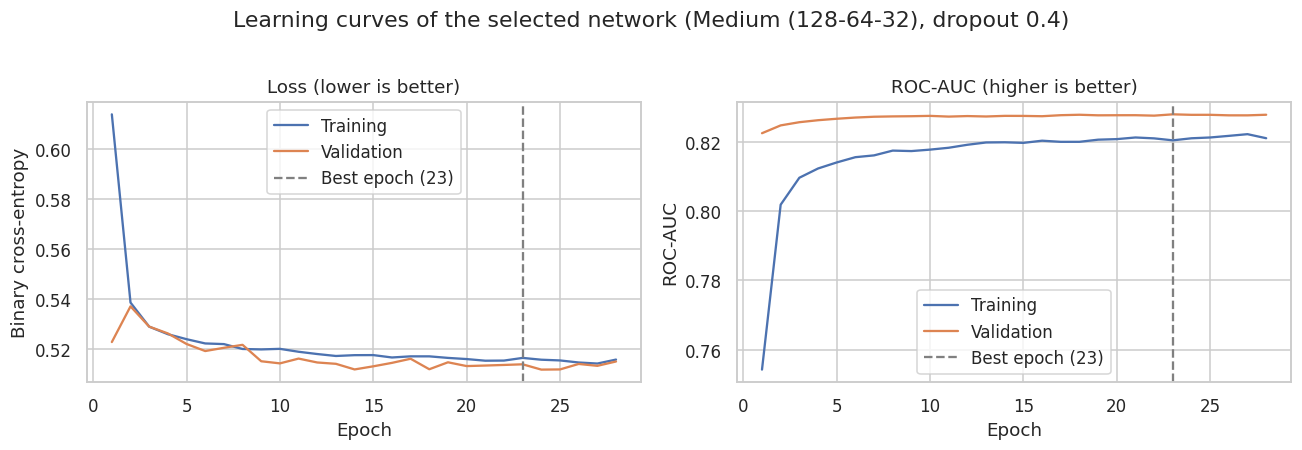

In [6]:
h = dnn_hist.history
epochs = np.arange(1, len(h['loss']) + 1)
best_epoch = int(np.argmax(h['val_auc']) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs, h['loss'], label='Training'); ax[0].plot(epochs, h['val_loss'], label='Validation')
ax[0].set(title='Loss (lower is better)', xlabel='Epoch', ylabel='Binary cross-entropy')
ax[1].plot(epochs, h['auc'], label='Training'); ax[1].plot(epochs, h['val_auc'], label='Validation')
ax[1].set(title='ROC-AUC (higher is better)', xlabel='Epoch', ylabel='ROC-AUC')
for a in ax:
    a.axvline(best_epoch, color='gray', ls='--', label=f'Best epoch ({best_epoch})')
    a.legend()
plt.suptitle(f'Learning curves of the selected network ({best_key[0]}, dropout {best_key[1]})', y=1.02)
plt.tight_layout()
plt.savefig(IMG + 'dnn_learning_curves.png', bbox_inches='tight'); plt.show()

**Reading the learning curves**

- **No overfitting.** The training and validation loss curves track each other closely for all 28 epochs, and the gap does not widen. Overfitting would show validation getting worse while training keeps improving.
- Training ROC-AUC (0.820 at the best epoch) is actually *below* validation ROC-AUC (0.828). That is normal here because dropout and batch normalization add noise during training but are switched off when scoring, so the training numbers are measured under harder conditions.
- Performance flattens after about 10 epochs. Training longer or adding capacity would not help; the limit is **how much information the 21 survey answers contain**, not the network's capacity. This agrees with Section 3 (bigger networks gave no gain) and with Notebook 2 (tuned boosting and a simple logistic regression are almost equal).
- Early stopping picked epoch 23 as the best version of the network.

## 5. Final Comparison of All Four Models on the Test Set
All four models are now scored on exactly the same 50,736 held-out people. Because the test set is only a sample, any score has some uncertainty. We therefore also compute **95% confidence intervals using the bootstrap** (re-scoring 200 random resamples of the test set) to see whether differences between models are bigger than chance.

In [7]:
proba = {name: classical[name].values for name in classical.columns[1:]}
proba['Deep Neural Network'] = dnn_test_proba

def evaluate(name, y_true, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {'Model': name, 'ROC-AUC': roc_auc_score(y_true, p), 'PR-AUC': average_precision_score(y_true, p),
            'Recall': recall_score(y_true, pred), 'Precision': precision_score(y_true, pred),
            'F1': f1_score(y_true, pred), 'Accuracy': accuracy_score(y_true, pred)}

final_table = pd.DataFrame([evaluate(n, y_test, p) for n, p in proba.items()]).set_index('Model')
final_table = final_table.sort_values('ROC-AUC', ascending=False)
final_table.round(4)

,ROC-AUC,PR-AUC,Recall,Precision,F1,Accuracy
Model,,,,,,
Deep Neural Network,0.8250,0.4623,0.7896,0.3332,0.4686,0.7178
Gradient Boosting,0.8246,0.4623,0.7845,0.3355,0.4700,0.7212
Random Forest,0.8221,0.4581,0.7508,0.3468,0.4745,0.7379
Logistic Regression,0.8184,0.4418,0.7610,0.3415,0.4715,0.7311


In [8]:
# Bootstrap 95% confidence intervals (resample test people with replacement)
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.values
B = 200
boot_auc = {n: [] for n in proba}; boot_pr = {n: [] for n in proba}
for _ in range(B):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    for n, p in proba.items():
        boot_auc[n].append(roc_auc_score(y_arr[idx], p[idx]))
        boot_pr[n].append(average_precision_score(y_arr[idx], p[idx]))

ci = pd.DataFrame({
    'ROC-AUC': final_table['ROC-AUC'],
    'ROC-AUC 95% CI': [f'{np.percentile(boot_auc[n], 2.5):.4f} - {np.percentile(boot_auc[n], 97.5):.4f}' for n in final_table.index],
    'PR-AUC': final_table['PR-AUC'],
    'PR-AUC 95% CI': [f'{np.percentile(boot_pr[n], 2.5):.4f} - {np.percentile(boot_pr[n], 97.5):.4f}' for n in final_table.index],
}).round(4)
display(ci)

# Paired differences: is the DNN really different from each classical model?
print('\nDNN minus other model (paired bootstrap, ROC-AUC):')
for n in ['Logistic Regression', 'Random Forest', 'Gradient Boosting']:
    diff = np.array(boot_auc['Deep Neural Network']) - np.array(boot_auc[n])
    print(f'  vs {n:20s}: {diff.mean():+.4f}  (95% CI {np.percentile(diff, 2.5):+.4f} to {np.percentile(diff, 97.5):+.4f})')

,ROC-AUC,ROC-AUC 95% CI,PR-AUC,PR-AUC 95% CI
Model,,,,
Deep Neural Network,0.8250,0.8208 - 0.8303,0.4623,0.4508 - 0.4743
Gradient Boosting,0.8246,0.8202 - 0.8294,0.4623,0.4510 - 0.4742
Random Forest,0.8221,0.8175 - 0.8271,0.4581,0.4470 - 0.4708
Logistic Regression,0.8184,0.8140 - 0.8232,0.4418,0.4307 - 0.4531



DNN minus other model (paired bootstrap, ROC-AUC):
  vs Logistic Regression : +0.0067  (95% CI +0.0056 to +0.0080)
  vs Random Forest       : +0.0030  (95% CI +0.0021 to +0.0040)
  vs Gradient Boosting   : +0.0005  (95% CI -0.0004 to +0.0014)


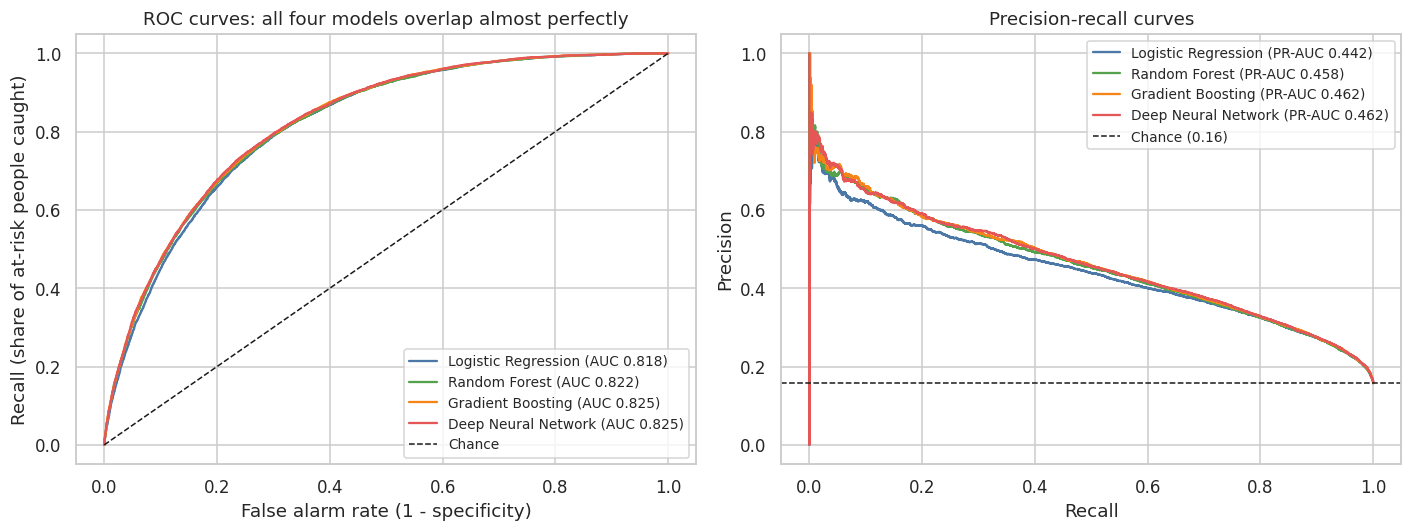

In [9]:
# ROC and precision-recall curves for all four models
colors = {'Logistic Regression': '#4C78A8', 'Random Forest': '#54A24B', 'Gradient Boosting': '#F58518', 'Deep Neural Network': '#E45756'}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, color=colors[n], label=f'{n} (AUC {roc_auc_score(y_test, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, color=colors[n], label=f'{n} (PR-AUC {average_precision_score(y_test, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
ax[0].set(title='ROC curves: all four models overlap almost perfectly', xlabel='False alarm rate (1 - specificity)', ylabel='Recall (share of at-risk people caught)')
ax[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'Chance ({y_test.mean():.2f})')
ax[1].set(title='Precision-recall curves', xlabel='Recall', ylabel='Precision')
for a in ax: a.legend(loc='lower right' if a is ax[0] else 'upper right', fontsize=9)
plt.tight_layout()
plt.savefig(IMG + 'model_comparison_curves.png', bbox_inches='tight'); plt.show()

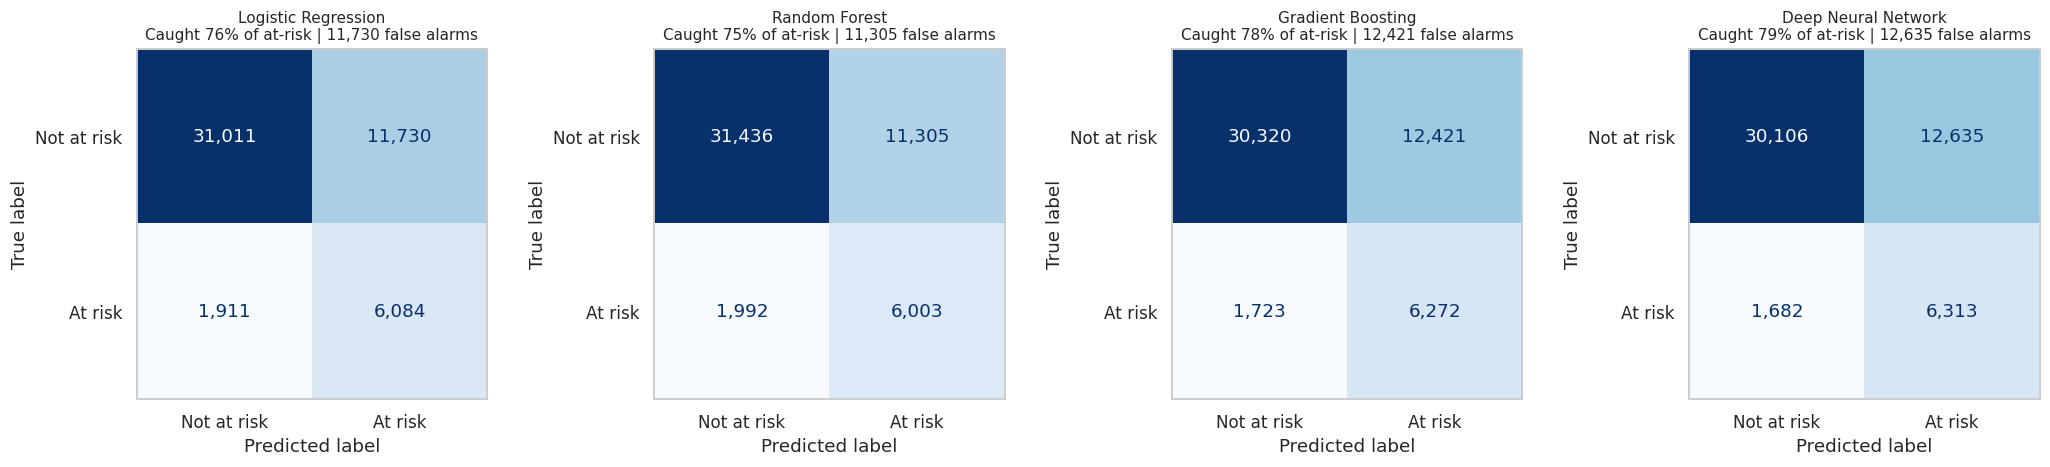

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, (n, p) in zip(axes, proba.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['Not at risk', 'At risk']).plot(ax=ax, cmap='Blues', colorbar=False, values_format=',d')
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f'{n}\nCaught {tp/(tp+fn):.0%} of at-risk | {fp:,} false alarms', fontsize=10); ax.grid(False)
plt.tight_layout()
plt.savefig(IMG + 'confusion_matrices_all_models.png', bbox_inches='tight'); plt.show()

### Does the deep neural network beat the simpler models?

**Short answer: it matches the best of them, but does not meaningfully beat them.**

| Model | Test ROC-AUC (95% CI) | Test PR-AUC | Recall at 0.5 | Precision at 0.5 |
|---|---|---|---|---|
| Deep neural network | 0.825 (0.821-0.830) | 0.462 | 79% | 33% |
| Gradient boosting | 0.825 (0.820-0.829) | 0.462 | 78% | 34% |
| Random forest | 0.822 (0.818-0.827) | 0.458 | 75% | 35% |
| Logistic regression | 0.818 (0.814-0.823) | 0.442 | 76% | 34% |

- **DNN vs. gradient boosting: a statistical tie.** The difference is +0.0005 ROC-AUC and its 95% interval (-0.0004 to +0.0014) includes zero. Their ROC and precision-recall curves are visually on top of each other.
- **DNN vs. random forest and logistic regression:** the DNN is ahead by 0.003 and 0.007 ROC-AUC, and these intervals exclude zero, so the gaps are real. But they are *tiny in practical terms*; the four ROC curves overlap almost perfectly.
- **Recall and precision at the 0.5 cut-off differ by only a few percentage points** and depend on the arbitrary cut-off, which Section 6 handles properly.

**Choosing the model to recommend.** Because the DNN and gradient boosting are tied, we prefer **gradient boosting for the screening tool**: it trains in a few seconds (the network needs about a minute), is smaller and simpler to deploy, and gives the same quality. We keep **logistic regression for explaining** the drivers of risk, because each of its weights has a direct meaning. The extra complexity of a deep network is not justified by this data. This is a useful, honest result: *more complex does not mean better when the inputs are a modest set of survey answers.*

## 6. Turning a Risk Score into a Screening Policy
The models output a **risk score** between 0 and 1. A health program must decide the **cut-off**: everyone above it is invited for a blood test. A lower cut-off catches more at-risk people (higher recall) but also invites more people who turn out to be fine (lower precision, more cost).

To avoid cheating, we choose the cut-off **without touching the test set**: we use out-of-sample predictions on the *training* data (5-fold cross-validated predictions), find the cut-off that achieves a target recall, and then apply that cut-off once to the test set.

We use the model recommended in the previous section.

In [11]:
FINAL_MODEL = 'Gradient Boosting'
print('Model used for screening analysis:', FINAL_MODEL)

# Out-of-sample risk scores on the training data (never used to pick the cut-off from test data)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
if FINAL_MODEL == 'Deep Neural Network':
    oof_scores, oof_truth = dnn_val_proba, y_val.values            # validation slice predictions
else:
    estimators = {
        'Logistic Regression': Pipeline([('scale', StandardScaler()),
            ('model', LogisticRegression(solver='saga', class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE,
                                         C=best_params['Logistic Regression']['model__C'],
                                         l1_ratio=best_params['Logistic Regression']['model__l1_ratio']))]),
        'Gradient Boosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE,
                                                            **best_params['Gradient Boosting']),
        'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', n_jobs=1,
                                                random_state=RANDOM_STATE, **best_params['Random Forest']),
    }
    oof_scores = cross_val_predict(clone(estimators[FINAL_MODEL]), X_train, y_train, cv=cv5, method='predict_proba')[:, 1]
    oof_truth = y_train.values

test_scores = proba[FINAL_MODEL]
rows = []
for target_recall in [0.70, 0.75, 0.80, 0.85, 0.90]:
    # highest cut-off whose recall on the out-of-sample training scores is at least the target
    prec, rec, thr = precision_recall_curve(oof_truth, oof_scores)
    cutoff = thr[np.where(rec[:-1] >= target_recall)[0].max()]
    pred = (test_scores >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'Target recall': f'{target_recall:.0%}', 'Risk-score cut-off': round(float(cutoff), 3),
                 'Actual recall on test': round(tp / (tp + fn), 3),
                 'Precision on test': round(tp / (tp + fp), 3),
                 '% of population flagged': round(100 * pred.mean(), 1),
                 'People tested per case found': round((tp + fp) / tp, 1)})
policy = pd.DataFrame(rows)
policy

Model used for screening analysis: Gradient Boosting


,Target recall,Risk-score cut-off,Actual recall on test,Precision on test,% of population flagged,People tested per case found
0,70%,0.582,0.697,0.375,29.3,2.7
1,75%,0.539,0.745,0.354,33.2,2.8
2,80%,0.489,0.795,0.331,37.9,3.0
3,85%,0.427,0.844,0.305,43.6,3.3
4,90%,0.347,0.896,0.277,50.9,3.6


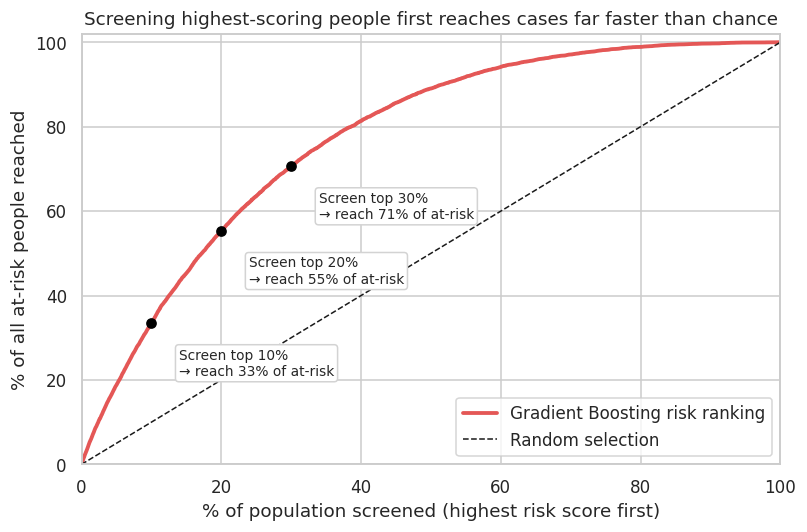

Screening the top 10% by risk score reaches 33% of at-risk people (random selection would reach 10%).
Screening the top 20% by risk score reaches 55% of at-risk people (random selection would reach 20%).
Screening the top 30% by risk score reaches 71% of at-risk people (random selection would reach 30%).


In [12]:
# Cumulative gains: if we screen people in order of risk score, how many at-risk people do we reach?
order = np.argsort(-test_scores)
cum_found = np.cumsum(y_test.values[order]) / y_test.sum()
share_screened = np.arange(1, len(order) + 1) / len(order)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(share_screened * 100, cum_found * 100, color='#E45756', lw=2.5, label=f'{FINAL_MODEL} risk ranking')
ax.plot([0, 100], [0, 100], 'k--', lw=1, label='Random selection')
for frac in (0.10, 0.20, 0.30):
    i = int(frac * len(order)) - 1
    ax.scatter(frac * 100, cum_found[i] * 100, color='black', zorder=5)
    ax.annotate(f'Screen top {frac:.0%}\n→ reach {cum_found[i]:.0%} of at-risk', (frac * 100, cum_found[i] * 100),
                textcoords='offset points', xytext=(18, -34), fontsize=9,
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='lightgray'))
ax.set(xlabel='% of population screened (highest risk score first)', ylabel='% of all at-risk people reached',
       title='Screening highest-scoring people first reaches cases far faster than chance', xlim=(0, 100), ylim=(0, 102))
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(IMG + 'cumulative_gains.png', bbox_inches='tight'); plt.show()

for frac in (0.10, 0.20, 0.30):
    print(f'Screening the top {frac:.0%} by risk score reaches {cum_found[int(frac*len(order))-1]:.0%} of at-risk people '
          f'(random selection would reach {frac:.0%}).')

**What this means for a screening program** (gradient boosting, test set of 50,736 people, 7,995 of them at risk):

- **A cut-off of about 0.49 catches about 80% of at-risk people.** It flags about 38% of the population, and about **3 people must be tested to find 1 at-risk person**, versus about 6 if people were chosen at random (the at-risk share is 16%).
- **The trade-off is explicit.** Going up to ~90% recall means flagging about half the population (3.6 people tested per case found). Settling for ~70% recall flags 29% (2.7 per case). A program with a small budget would pick a higher cut-off, one with generous capacity a lower one.
- **Prioritizing by risk score works even without a fixed cut-off:** screening the top 10% of scores reaches 33% of at-risk people, the top 20% reaches 55%, and the top 30% reaches 71%. That is roughly 2.4 to 3.3 times as many cases as choosing people at random would reach.
- **Remember what "false alarm" means here.** The survey label marks someone as "not at risk" if they have not been *diagnosed*. Some people flagged by the model may have undiagnosed prediabetes or diabetes, which is exactly who screening is meant to find. So real-world precision may be better than the 33% measured here.

## 7. What Drives Risk?

We use two complementary views:

1. **Permutation importance** (for the screening model): shuffle one feature at a time on the test set and measure how much the ROC-AUC drops. A big drop means the model relied heavily on that feature. This works for *any* model, including the neural network.
2. **Logistic-regression odds ratios**: for direction. Permutation importance says *how much* a feature matters, but not whether more of it raises or lowers risk. The odds ratio is per 1 standard-deviation increase in the feature, holding the others fixed.

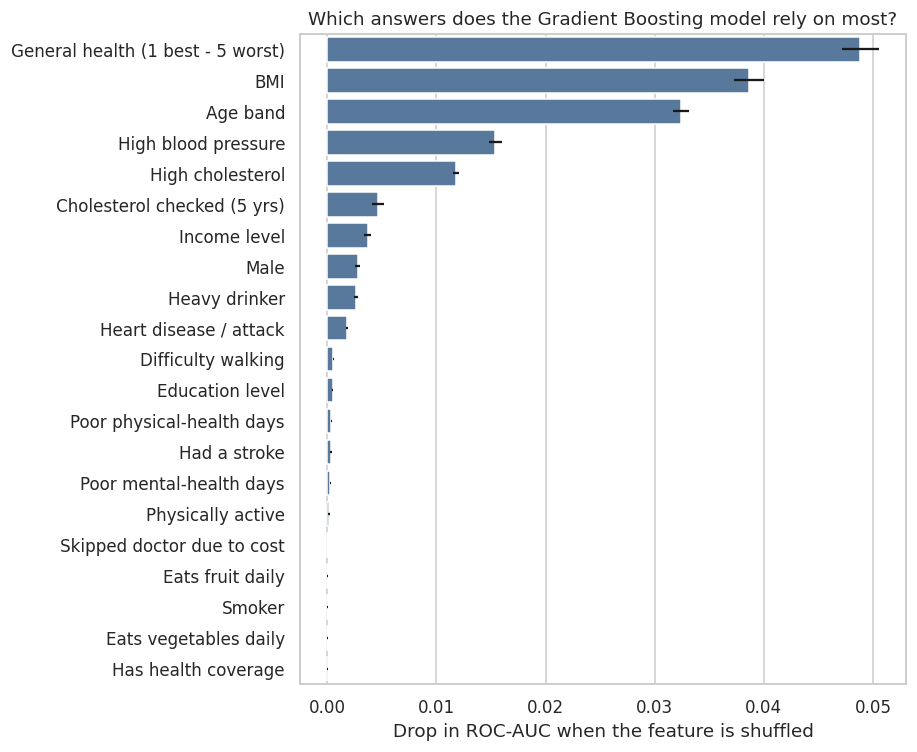

,Feature,importance
0,General health (1 best - 5 worst),0.0488
1,BMI,0.0386
2,Age band,0.0324
3,High blood pressure,0.0154
4,High cholesterol,0.0118
5,Cholesterol checked (5 yrs),0.0047
6,Income level,0.0037
7,Male,0.0028


In [13]:
nice = {'HighBP': 'High blood pressure', 'HighChol': 'High cholesterol', 'CholCheck': 'Cholesterol checked (5 yrs)', 'BMI': 'BMI',
        'Smoker': 'Smoker', 'Stroke': 'Had a stroke', 'HeartDiseaseorAttack': 'Heart disease / attack',
        'PhysActivity': 'Physically active', 'Fruits': 'Eats fruit daily', 'Veggies': 'Eats vegetables daily',
        'HvyAlcoholConsump': 'Heavy drinker', 'AnyHealthcare': 'Has health coverage', 'NoDocbcCost': 'Skipped doctor due to cost',
        'GenHlth': 'General health (1 best - 5 worst)', 'MentHlth': 'Poor mental-health days', 'PhysHlth': 'Poor physical-health days',
        'DiffWalk': 'Difficulty walking', 'Sex': 'Male', 'Age': 'Age band', 'Education': 'Education level', 'Income': 'Income level'}

def permutation_importance_auc(predict_fn, X_df, y_true, n_repeats=5, seed=RANDOM_STATE):
    # Mean drop in ROC-AUC when one column at a time is shuffled
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y_true, predict_fn(X_df))
    out = {}
    for col in X_df.columns:
        drops = []
        for _ in range(n_repeats):
            Xp = X_df.copy()
            Xp[col] = rng.permutation(Xp[col].values)
            drops.append(base - roc_auc_score(y_true, predict_fn(Xp)))
        out[col] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=['importance', 'std']).T.sort_values('importance', ascending=False)

if FINAL_MODEL == 'Deep Neural Network':
    predict_fn = lambda d: dnn.predict(scaler.transform(d), verbose=0).ravel()
else:
    final_estimator = clone(estimators[FINAL_MODEL]).fit(X_train, y_train)
    predict_fn = lambda d: final_estimator.predict_proba(d)[:, 1]

perm = permutation_importance_auc(predict_fn, X_test, y_test)
perm['Feature'] = perm.index.map(nice)

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.barplot(data=perm, y='Feature', x='importance', color='#4C78A8', xerr=perm['std'], ax=ax)
ax.set(title=f'Which answers does the {FINAL_MODEL} model rely on most?', xlabel='Drop in ROC-AUC when the feature is shuffled', ylabel='')
plt.tight_layout()
plt.savefig(IMG + 'permutation_importance.png', bbox_inches='tight'); plt.show()
perm[['Feature', 'importance']].head(8).round(4).reset_index(drop=True)

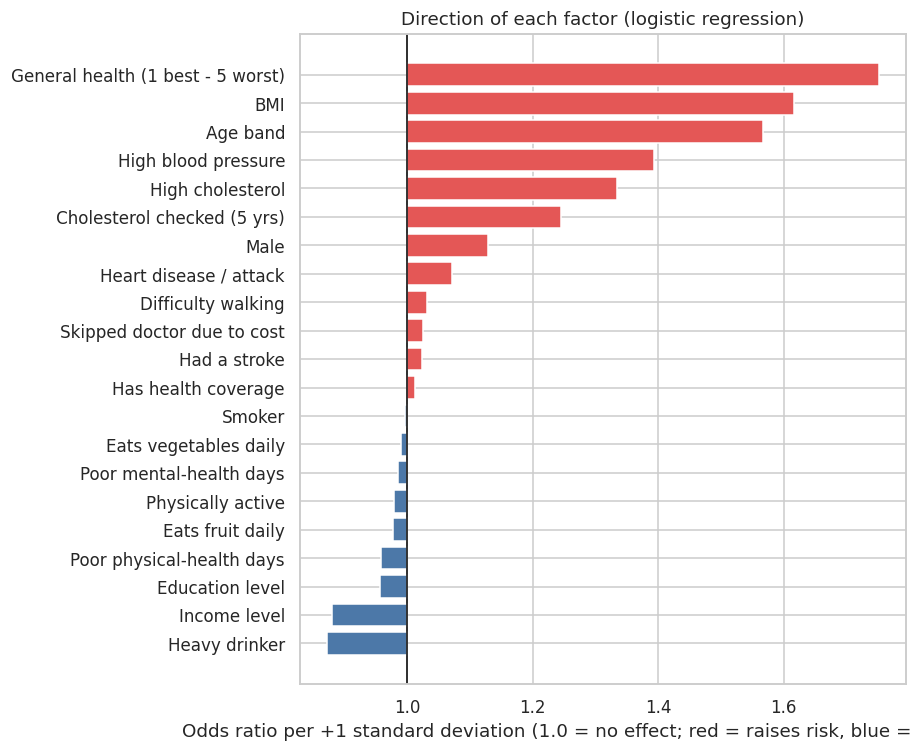

,Feature,Odds ratio per +1 SD
0,General health (1 best - 5 worst),1.75
1,BMI,1.62
2,Age band,1.57
3,High blood pressure,1.39
4,High cholesterol,1.33
5,Cholesterol checked (5 yrs),1.25
6,Male,1.13
7,Heart disease / attack,1.07
8,Difficulty walking,1.03
9,Skipped doctor due to cost,1.02


In [14]:
# Logistic regression odds ratios (per +1 standard deviation), refit on the full training set with the tuned settings
lr_final = Pipeline([('scale', StandardScaler()),
                     ('model', LogisticRegression(solver='saga', class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE,
                                                  C=best_params['Logistic Regression']['model__C'],
                                                  l1_ratio=best_params['Logistic Regression']['model__l1_ratio']))]).fit(X_train, y_train)
odds = pd.DataFrame({'Feature': [nice[c] for c in X.columns],
                     'Odds ratio per +1 SD': np.exp(lr_final.named_steps['model'].coef_[0])}).sort_values('Odds ratio per +1 SD')

fig, ax = plt.subplots(figsize=(8.5, 7))
colors_or = ['#E45756' if v > 1 else '#4C78A8' for v in odds['Odds ratio per +1 SD']]
ax.barh(odds['Feature'], odds['Odds ratio per +1 SD'] - 1, left=1, color=colors_or)
ax.axvline(1, color='black', lw=1)
ax.set(xlabel='Odds ratio per +1 standard deviation (1.0 = no effect; red = raises risk, blue = lowers risk)',
       title='Direction of each factor (logistic regression)')
plt.tight_layout()
plt.savefig(IMG + 'odds_ratios.png', bbox_inches='tight'); plt.show()
odds.sort_values('Odds ratio per +1 SD', ascending=False).round(2).reset_index(drop=True)

**What the two views say**

- **Three factors dominate:** self-rated **general health** (largest effect), **BMI** and **age**. Shuffling any of them costs the model 0.03-0.05 ROC-AUC, at least twice as much as any other feature. **High blood pressure** and **high cholesterol** are the next most important (0.015 and 0.012).
- **Direction (odds ratios per +1 standard deviation):** worse general health (1.75), higher BMI (1.62), older age (1.57), high blood pressure (1.39) and high cholesterol (1.33) all raise the odds of being at risk. Higher **income** (0.88) lowers them.
- **Many features add almost nothing once the main ones are known.** Difficulty walking, heart disease, stroke, smoking, diet and physical activity all looked clearly linked to diabetes on their own in Notebook 1, but their odds ratios here are close to 1. Reason: they overlap heavily with general health, age, blood pressure and BMI, so the model gets most of the same information from those. This does **not** mean these things are harmless; it means they are not *extra* information for prediction.
- **Be careful with two results that are not real risk factors:**
  - **"Cholesterol checked in the past 5 years"** ranks 6th and raises risk (1.25). This reflects *detection*: people who see doctors are more likely to have been diagnosed. It is a marker of contact with healthcare, not a cause.
  - **"Heavy drinker"** appears *protective* (0.87). As noted in Notebook 1, this is probably because people diagnosed with diabetes are advised to cut back on alcohol and because of who reports heavy drinking. It is **not** evidence that drinking prevents diabetes.
- **These are associations, not causes.** The model shows what *predicts* a diagnosis, not what would change it if altered.

## 8. Fairness Check: Does the Model Work Equally Well for Different Groups?
A screening tool that works well for one group and poorly for another can widen health inequalities. We check ROC-AUC and recall (at the cut-off chosen for ~80% overall recall) by **sex, age group and income group** on the test set.

,Group,Level,People,Actual at-risk share,ROC-AUC,Recall,Precision
0,Sex,Female,28192,0.148,0.839,0.791,0.337
1,Sex,Male,22544,0.170,0.806,0.800,0.324
2,Age group,18-44,10914,0.047,0.845,0.431,0.263
3,Age group,45-64,22230,0.155,0.819,0.767,0.334
4,Age group,65+,17592,0.229,0.768,0.866,0.334
5,Income group,Under $25k,11552,0.259,0.782,0.889,0.377
6,Income group,$25-50k,12458,0.173,0.798,0.814,0.313
7,Income group,$50k+,26726,0.107,0.832,0.682,0.296


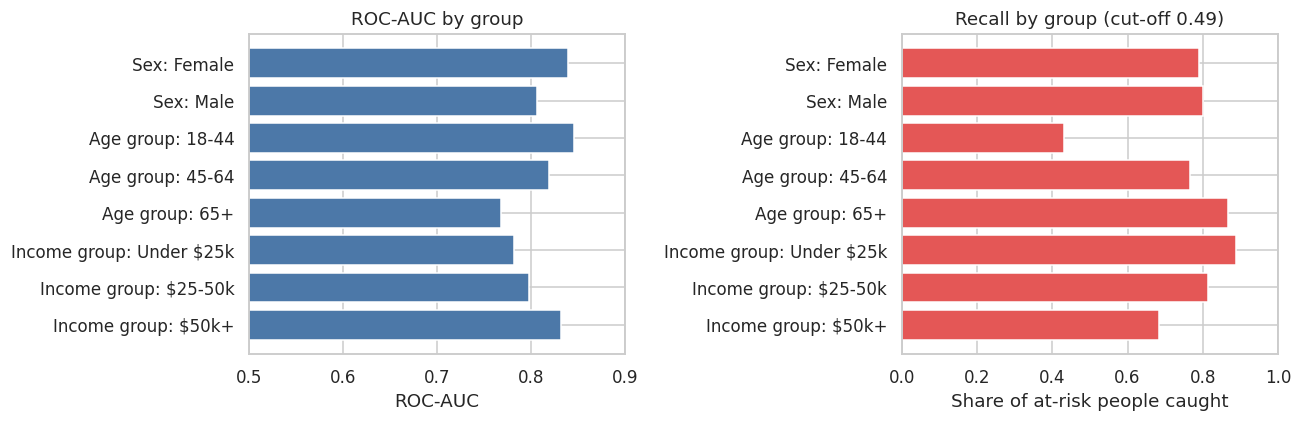

In [15]:
cut80 = float(policy.loc[policy['Target recall'] == '80%', 'Risk-score cut-off'].iloc[0])
groups = pd.DataFrame({
    'Sex': X_test['Sex'].map({0: 'Female', 1: 'Male'}),
    'Age group': pd.cut(X_test['Age'], bins=[0, 5, 9, 13], labels=['18-44', '45-64', '65+']),
    'Income group': pd.cut(X_test['Income'], bins=[0, 4, 6, 8], labels=['Under $25k', '$25-50k', '$50k+']),
}, index=X_test.index)

rows = []
for gcol in groups.columns:
    for level in groups[gcol].cat.categories if hasattr(groups[gcol], 'cat') else sorted(groups[gcol].unique()):
        m = (groups[gcol] == level).values
        pred = (test_scores[m] >= cut80).astype(int)
        rows.append({'Group': gcol, 'Level': level, 'People': int(m.sum()), 'Actual at-risk share': y_test.values[m].mean(),
                     'ROC-AUC': roc_auc_score(y_test.values[m], test_scores[m]),
                     'Recall': recall_score(y_test.values[m], pred), 'Precision': precision_score(y_test.values[m], pred)})
fair = pd.DataFrame(rows)
display(fair.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
lab = fair['Group'] + ': ' + fair['Level'].astype(str)
ax[0].barh(lab, fair['ROC-AUC'], color='#4C78A8'); ax[0].set(xlim=(0.5, 0.9), title='ROC-AUC by group', xlabel='ROC-AUC')
ax[1].barh(lab, fair['Recall'], color='#E45756'); ax[1].set(xlim=(0, 1), title=f'Recall by group (cut-off {cut80:.2f})', xlabel='Share of at-risk people caught')
for a in ax: a.invert_yaxis()
plt.tight_layout()
plt.savefig(IMG + 'fairness_by_group.png', bbox_inches='tight'); plt.show()

**What the fairness check shows**

- **The ranking quality (ROC-AUC) is decent for every group (0.77-0.85)** but lowest for people 65+ (0.77) and for men (0.81). Among older people almost everyone has an elevated score, so it is harder to separate those truly at risk.
- **The bigger concern is recall at a single cut-off.** With one cut-off (0.49), the model catches **87% of at-risk people aged 65+ but only 43% of those aged 18-44**, and **89% of those earning under $25k but only 68% of those earning $50k+**. Precision is similar across groups (26-38%).
- **Why it happens:** the risk score partly reflects how common diabetes is in a group (4.7% in 18-44 vs. 22.9% in 65+). A younger or higher-income person who is at risk usually looks "healthier on paper", so their score is lower and more of them fall below the cut-off.
- **Implication:** a single national cut-off would, in practice, direct most screening to older and lower-income people and under-detect at-risk younger and higher-income people. A real program should consider **age-specific cut-offs** (or a different target recall per group) and monitor results by group. Younger adults are a small share of all at-risk people (about 6% in this test set) but they are the group where early prevention could have the longest-lasting benefit.
- Sex differences are small for recall (79% vs. 80%).

## 9. Conclusions

### Answer to the research question
**Yes, but modestly, and a deep neural network is not needed.** Using only 21 everyday survey answers, models can rank people by diabetes/prediabetes risk with a **ROC-AUC of about 0.82**: given one at-risk and one not-at-risk person, the model gives the at-risk person the higher score about 82% of the time. A deep neural network (0.825) **ties gradient boosting (0.825)** and is only marginally ahead of random forest (0.822) and logistic regression (0.818). The ceiling is set by the information in the data, not by the model.

### Key findings
1. **Three answers do most of the work:** self-rated general health, BMI and age, followed by high blood pressure and high cholesterol.
2. **As a screening aid it is useful:** at a cut-off that catches about 80% of at-risk people it flags about 38% of the population (about 3 tests per case found); prioritizing the top 30% by risk score reaches 71% of at-risk people.
3. **Complexity did not pay off:** network size, extra layers and a wider boosting search made no practical difference.
4. **Performance is uneven across groups** at a single cut-off (much lower recall for ages 18-44 and higher-income people).

### Recommendations for decision-makers (non-technical)
- **Use it to decide *who to invite for a blood test first*, not to diagnose anyone.** The tool narrows who to test; only a lab test confirms diabetes.
- **Pick the cut-off to match capacity:** a bigger screening budget supports a lower cut-off (more cases found, more tests per case).
- **Set group-specific targets** (especially by age) so younger at-risk people are not systematically missed, and track results by group.
- **Target the modifiable drivers:** blood pressure, cholesterol and weight management programs reach the same people the model flags.
- **Prefer the simplest adequate model.** Gradient boosting (to score people) plus logistic regression (to explain results) give the same performance as a neural network at a fraction of the complexity and cost.

### Limitations
- **Self-reported survey data (US adults, 2015)** with no lab values; the labels reflect *diagnosed* conditions, so undiagnosed cases are counted as "not at risk".
- **Prediabetes was merged with diabetes.** It is only 1.8% of the sample, too rare to model separately, so the model cannot tell the two apart.
- **Precision is about 1 in 3.** Most people flagged are not at risk by the survey label (though some may have undiagnosed disease).
- **Associations, not causes**, and a few results (heavy drinking, cholesterol check) reflect reporting and detection effects.
- **One data year, one split, one training run per network;** differences smaller than about 0.002 ROC-AUC should not be over-interpreted.

### Next steps
1. **Validate on newer BRFSS years or another population** before any real use.
2. **Add objective measurements** (e.g., fasting glucose, HbA1c, waist circumference) if available; they would likely raise the ceiling far more than any model change.
3. **Build group-aware cut-offs** and evaluate fairness formally.
4. **Model prediabetes separately** if more data on it can be obtained.
5. **Calibrate the scores into real probabilities** and choose the cut-off with explicit costs (cost of a test vs. cost of a missed case).